<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet6%20(ANN)%20PBL/Praktikum%201%20(JS6)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Instalasi Library & Persiapan Dataset (cafes.csv & reviews.csv)

In [1]:
# Instalasi Annoy (jalankan di sel terpisah jika di Colab)
!pip install annoy

import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from annoy import AnnoyIndex
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import euclidean_distances

# Load dataset
cafes = pd.read_csv('cafes.csv')
reviews = pd.read_csv('reviews.csv')

# Agregasi data reviews per cafe
reviews_agg = reviews.groupby('cafe_id').agg(
    avg_review_rating=('rating', 'mean'),
    total_likes=('likes', 'sum')
).reset_index()

# Gabungkan dengan dataframe cafes
merged = pd.merge(cafes, reviews_agg, on='cafe_id', how='left').fillna(0)
print(f"Total Cafe setelah digabung: {merged.shape[0]} baris")
merged.head(3)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 3.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520032 sha256=69d91f9d25011e65eedf768708002b6cf34b9b675eaf2e512b719c80180bedd7
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy
Total Cafe setelah digabung: 99 baris


,cafe_id,name,address,latitude,longitude,rating,review_count,categories,phone,website,scraped_at,source_query,avg_review_rating,total_likes
0,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang,4.400000,0.0
1,528dfd21-83c6-4946-ab05-391e238caa4a,Nayanika Coffee & Eatery - Malang,"Jl. Brigjend Slamet Riadi No.173, Oro-oro Dowo...",-7.963825,112.627146,4.7,141,['Kafe'],0851-4820-4378,linktr.ee,2026-10-11T13:54:56.561971,cafe Kota Malang,4.866667,0.0
2,cb007499-1d5e-4613-8bbc-c0d30e17b2d2,The Grove Cafe Malang,"Jl. Wilis No.23, Gading Kasri, Kec. Klojen, Ko...",-7.972555,112.618455,4.6,1772,['Kafe'],0888-8299-000,0,2026-10-11T13:55:10.909678,cafe Kota Malang,4.217391,0.0


#Langkah 2: Percobaan 1 - Exact NN vs Annoy (2 Dimensi: Latitude & Longitude)

Query Cafe: Berkat Terang Jaya

--- Exact NN ---
Index: [51 23 96]
Nama Cafe:
                   name  latitude   longitude
51  Berkat Terang Jaya -7.970860  112.631363
23          Fajar Baru -7.968808  112.632215
96          Fajar Baru -7.968808  112.632215
Waktu Exact: 3.0363 ms

--- Annoy NN (3 Trees) ---
Index: [51, 23, 96]
Nama Cafe:
                   name  latitude   longitude
51  Berkat Terang Jaya -7.970860  112.631363
23          Fajar Baru -7.968808  112.632215
96          Fajar Baru -7.968808  112.632215
Waktu Annoy: 0.1669 ms


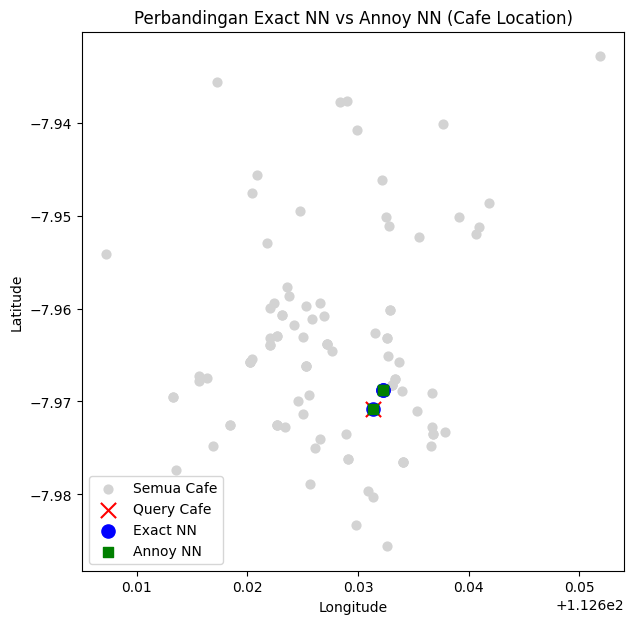

In [2]:
# 1. Dataset 2D dari koordinat Cafe
X_2d = merged[['latitude', 'longitude']].values
n_points = len(X_2d)

# Pilih query point secara random dari dataset cafe
np.random.seed(42)
query_idx = np.random.randint(0, n_points)
query_2d = X_2d[query_idx]

print(f"Query Cafe: {merged.loc[query_idx, 'name']}")

# 2. Exact NN (Brute Force)
start = time.time()
distances = np.linalg.norm(X_2d - query_2d, axis=1)
idx_exact = np.argsort(distances)[:3]  # Ambil 3 terdekat
time_exact = time.time() - start

print("\n--- Exact NN ---")
print("Index:", idx_exact)
print("Nama Cafe:\n", merged.loc[idx_exact, ['name', 'latitude', 'longitude']])
print("Waktu Exact:", round(time_exact * 1000, 4), "ms")

# 3. Annoy NN (3 trees)
f = 2  # 2 dimensi (latitude, longitude)
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X_2d):
    t.add_item(i, vec)
t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query_2d, 3)  # Cari 3 NN
time_ann = time.time() - start

print("\n--- Annoy NN (3 Trees) ---")
print("Index:", idx_ann)
print("Nama Cafe:\n", merged.loc[idx_ann, ['name', 'latitude', 'longitude']])
print("Waktu Annoy:", round(time_ann * 1000, 4), "ms")

# 4. Visualisasi Hasil
plt.figure(figsize=(7, 7))
plt.scatter(X_2d[:, 1], X_2d[:, 0], c="lightgray", s=40, label="Semua Cafe")
plt.scatter(query_2d[1], query_2d[0], c="red", marker="x", s=120, label="Query Cafe")
plt.scatter(X_2d[idx_exact, 1], X_2d[idx_exact, 0], c="blue", s=90, label="Exact NN")
plt.scatter(X_2d[idx_ann, 1], X_2d[idx_ann, 0], c="green", s=60, marker="s", label="Annoy NN")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.title("Perbandingan Exact NN vs Annoy NN (Cafe Location)")
plt.show()

#Langkah 3: Percobaan 2 - Sistem Rekomendasi Cafe Multi-Fitur

In [3]:
# Pilih fitur numerik multi-dimensi
feature_cols = ['latitude', 'longitude', 'rating', 'review_count', 'avg_review_rating', 'total_likes']
X_multi = merged[feature_cols].values

# Normalisasi fitur agar skala setara
scaler = StandardScaler()
X_multi_scaled = scaler.fit_transform(X_multi)

n_cafes, n_features = X_multi_scaled.shape
query_multi = X_multi_scaled[0].reshape(1, -1)  # Cafe pertama sebagai query

print(f"Query Cafe: {merged.loc[0, 'name']}")

# ---- 1. Exact NN (Brute Force) ----
start = time.time()
distances_multi = euclidean_distances(query_multi, X_multi_scaled)[0]
exact_idx = np.argsort(distances_multi)[:3]
exact_time = time.time() - start

print("\n--- Exact NN (Multi-Feature) ---")
print("Result Index:", exact_idx)
print("Recommended Cafes:\n", merged.loc[exact_idx, ['name', 'rating', 'review_count']])
print("Exact NN time:", round(exact_time * 1000, 4), "ms")

# ---- 2. Annoy NN ----
f = n_features
annoy_index = AnnoyIndex(f, 'euclidean')
n_trees = 8

for i in range(n_cafes):
    annoy_index.add_item(i, X_multi_scaled[i])
annoy_index.build(n_trees)

start = time.time()
annoy_idx = annoy_index.get_nns_by_vector(query_multi[0], 3)
annoy_time = time.time() - start

print("\n--- Annoy NN (8 Trees, Multi-Feature) ---")
print("Result Index:", annoy_idx)
print("Recommended Cafes:\n", merged.loc[annoy_idx, ['name', 'rating', 'review_count']])
print("Annoy time:", round(annoy_time * 1000, 4), "ms")

Query Cafe: ARTE COFFEE & EATERY

--- Exact NN (Multi-Feature) ---
Result Index: [ 0 11 31]
Recommended Cafes:
                     name  rating  review_count
0   ARTE COFFEE & EATERY     4.7           528
11  ARTE COFFEE & EATERY     4.7           528
31  ARTE COFFEE & EATERY     4.7           533
Exact NN time: 1.6763 ms

--- Annoy NN (8 Trees, Multi-Feature) ---
Result Index: [0, 11, 31]
Recommended Cafes:
                     name  rating  review_count
0   ARTE COFFEE & EATERY     4.7           528
11  ARTE COFFEE & EATERY     4.7           528
31  ARTE COFFEE & EATERY     4.7           533
Annoy time: 0.2091 ms


Pertanyaannya: Kenapa code dibagian build index tidak dihitung waktunya?

Jawab :    

Code di bagian build index (t.build(3) atau annoy_index.build(n_trees)) tidak dimasukkan ke dalam perhitungan waktu pencarian (query time) karena proses building index merupakan tahap prapemrosesan (offline phase), sedangkan fungsi pencarian (get_nns_by_vector) adalah tahap pengujian/pencarian (online phase).